# Init:

In [1]:
%load_ext autoreload
%autoreload 2

import os
import sys
import json
import asyncio
import nest_asyncio
from dotenv.main import load_dotenv

load_dotenv()
REPO_PATH = os.getenv('REPO_PATH')

sys.path.append(REPO_PATH)

nest_asyncio.apply()

def load_json(file_path):
    with open(file_path, "r", encoding="utf-8") as file:
        return json.load(file)

# 1. Load datasets:
Load all three source datasets and structure them as question-answer pairs.

In [2]:
from knowledge_maze.create_dataset.load_datasets import *

# Load all the input datasets, insert destanation path if saving is required.
tqa_dataset = load_tqa(f"{REPO_PATH}\data_files\extracted_nq.json")
nq_dataset = load_nq(f"{REPO_PATH}\data_files\extracted_squad.json")
sqd_dataset = load_sqd(f"{REPO_PATH}\data_files\extracted_triviaQA.json")

total_pairs = len(tqa_dataset) + len(nq_dataset) + len(sqd_dataset)
print(f'Loaded {total_pairs} question-answer pairs in total.')

ModuleNotFoundError: No module named 'ijson'

In [2]:
# Load from saved dataset:
tqa_dataset = load_json(f"{REPO_PATH}\data_files\extracted_nq.json")
nq_dataset = load_json(f"{REPO_PATH}\data_files\extracted_squad.json")
sqd_dataset = load_json(f"{REPO_PATH}\data_files\extracted_triviaQA.json")

# 2. Classify answers:
Classify answers by types - Wikipedia entities, numbers, dates and free-form.
We will merge all the candidate datasets and discard the free-form answer, also normalize the answers for easier comparison later.

In [3]:
from knowledge_maze.create_dataset.answer_classification import classify_dataset_answers

print('Processing TriviaQA:')
tqa_answer_types = await classify_dataset_answers(tqa_dataset, output_path=f"{REPO_PATH}\data_files\\tqa_answer_types.json")
print('Processing Natural Questions:')
nq_answer_types = await classify_dataset_answers(nq_dataset, output_path=f"{REPO_PATH}\data_files\\nq_answer_types.json")
print('Processing SQuAD:')
sqd_answer_types = await classify_dataset_answers(sqd_dataset, output_path=f"{REPO_PATH}\data_files\\sqd_answer_types.json")

Processing TriviaQA:


Classifying Answers: 100%|██████████████████████████████████████████████████████| 78260/78260 [03:16<00:00, 398.08it/s]


Processing Natural Questions:


Classifying Answers: 100%|████████████████████████████████████████████████████| 106926/106926 [04:22<00:00, 407.29it/s]


Processing SQuAD:


Classifying Answers: 100%|██████████████████████████████████████████████████████| 86821/86821 [03:09<00:00, 459.15it/s]


In [4]:
# Load from saved dataset:
tqa_answer_types = load_json(f"{REPO_PATH}\data_files\\tqa_answer_types.json")
nq_answer_types = load_json(f"{REPO_PATH}\data_files\\nq_answer_types.json")
sqd_answer_types = load_json(f"{REPO_PATH}\data_files\\sqd_answer_types.json")

Merged dataset contains 209055 Q-A pairs out of original 272007(77%).


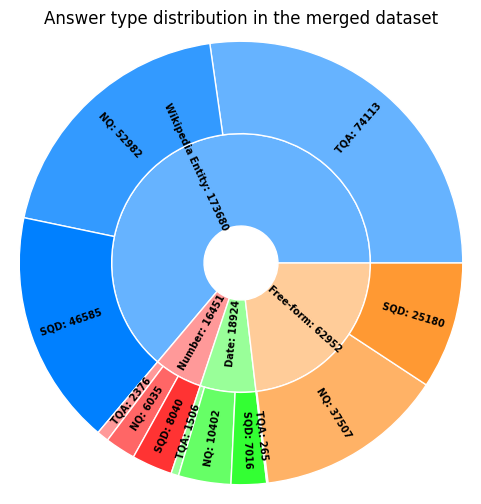

In [4]:
# Merge datasets and visualize results:
from knowledge_maze.create_dataset.answer_classification import merge_datasets

merged_dataset = merge_datasets({
                                     'TQA': tqa_answer_types,
                                     'NQ': nq_answer_types,
                                     'SQD': sqd_answer_types
                                },
                                output_path=f"{REPO_PATH}\data_files\\merged_dataset.json",
                                verbose=True)

In [10]:
# Print exapmles:
from random import choices

for sample in choices(merged_dataset, k=10):
    print(f"Question: {sample['Question']}")
    print(f"Answer: {sample['Answer']}")
    print(f"Type: {sample['Answer type']}")
    print(f"Normalized: {sample['Normalized answer']}")
    print(f"=" * 50)

Question: when did snow white and the seven dwarfs come out
Answer: 1937
Type: Date
Normalized: {'category': 'year', 'parsed_value': '1937'}
Question: What city in Rhode Island is famous for its many mansions built during the late 1800's?
Answer: Newport
Type: Wikipedia Entity
Normalized: Newport
Question: Erik the Red from Norway founded the first successful Norse settlement on Greenland, and then his son Leif continued the tradition of exploring west and landed where?
Answer: North America
Type: Wikipedia Entity
Normalized: North America
Question: What royal park shares a border with its neighbor, the park known as Kensington Gardens?
Answer: Hyde Park
Type: Wikipedia Entity
Normalized: Hyde Park
Question: How many earthquakes occurred on March 5, 2012?
Answer: twelve
Type: Number
Normalized: 12
Question: The Battle of Flodden took place in September 1513 in which English county?
Answer: Northumberland
Type: Wikipedia Entity
Normalized: Northumberland
Question: who won second place i

# 3. Group questions:

In [4]:
# Load from saved dataset:
merged_dataset = load_json(f"{REPO_PATH}\data_files\\merged_dataset.json")

In [11]:
import matplotlib.pyplot as plt
%matplotlib inline
from tqdm import tqdm
from knowledge_maze.create_dataset.group_questions import generate_embeddings, cluster_wiki_entities

In [12]:
# Divide by answer type:
ent_data = []
num_data = []
date_data = []
for sample in merged_dataset:
    if sample['Answer type'] == 'Wikipedia Entity':
        ent_data.append(sample)
    elif sample['Answer type'] == 'Number':
        num_data.append(sample)
    else:
        date_data.append(sample)

In [15]:
# Cluster question by answer:
ent_clusters = cluster_wiki_entities(ent_data)
num_clusters = cluster_wiki_entities(num_data)
# date_clusters = cluster_wiki_entities(date_data)
print(f'Total candidate clusters:')
print(f'Entities: {len(ent_clusters)}')
print(f'Numerical: {len(num_clusters)}')
# print(f'Date & Time: {len(date_clusters)}')

Clustering Entity Questions: 100%|██████████████████████████████████████████| 16451/16451 [00:00<00:00, 3168357.75it/s]

Total candidate clusters:
Entities: 24719
Numerical: 983


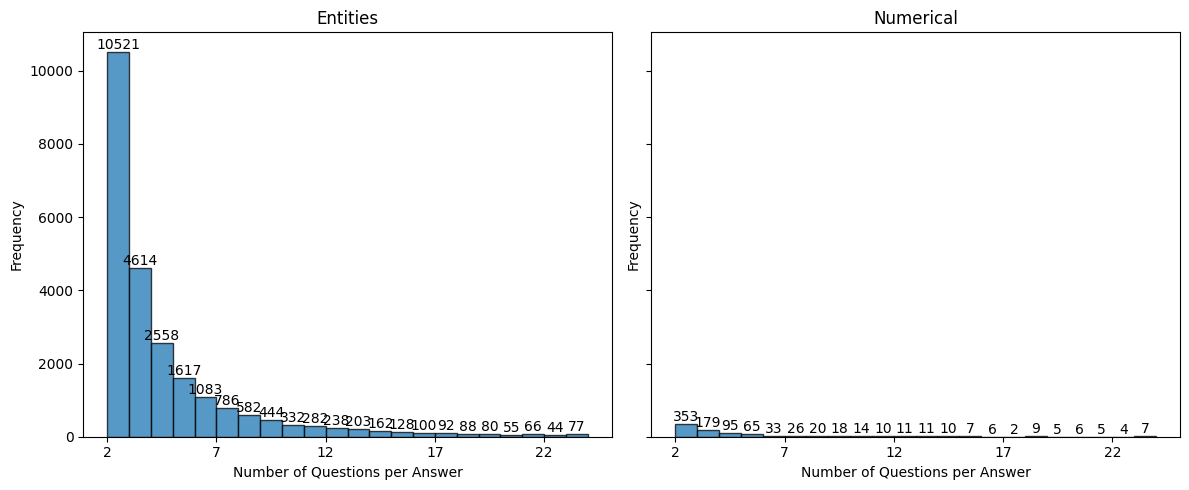

In [18]:
from knowledge_maze.create_dataset.group_questions import plot_answer_distributions
plot_answer_distributions({'Entities': ent_clusters, 'Numerical': num_clusters, 'Date & Time': date_clusters})

## 3.1 - Cluster and filter entity questions:

In [9]:
from knowledge_maze.create_dataset.group_questions import generate_question_embeddings
# Generate embeddings for all entity questions:
entity_questions_embeddings = generate_question_embeddings(ent_clusters, batch_size=2048)

 12%|█████████▊                                                                         | 8/68 [00:22<02:51,  2.86s/it]


KeyboardInterrupt: 

Answer: Marie Curie
Questions before filtring:
1. Who was the first woman to win a Nobel Prize?
2. Which scientist discovered the radioactive element Radium in 1898?
3. Who is (at 2012) the only person to have won a Nobel Prize for physics and chemistry?
4. Who is the next in this series: Adolf von Baeyer (1905), Henri Moissan (1906), Eduard Buchner (1907), Ernest Rutherford (1908), Wilhelm Ostwald (1909), Otto Wallach (1910) ... ?
5. What Frenchwoman won a Nobel Prize for chemistry?
6. What Parisienne was the first person to win multiple Nobel Prizes?
7. Sklodowska was the maiden name of which Nobel Prize winner?
8. Who was the first and to date the only woman to have won two Nobel prizes
9. Who was the first person known to have died from the effects of radiation
10. In 1903 who became the first woman to receive the Nobel Prize?
11. which scientist lost their life in consequence of their discovery
12. scientist who lost life in their own discovery
13. Who isolated radium in uranium o

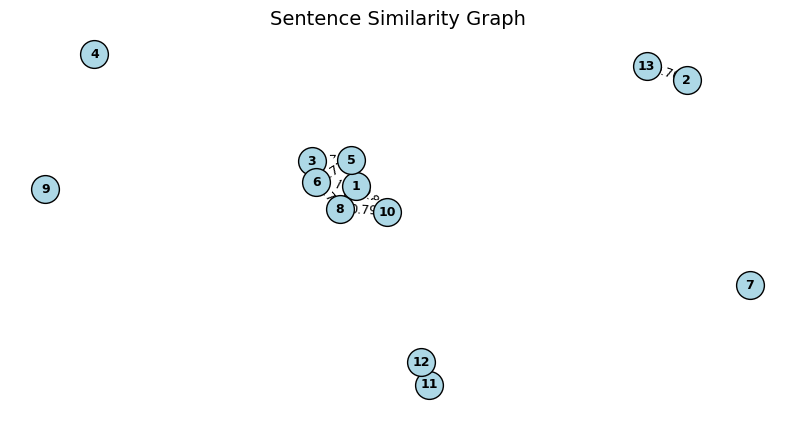

Questions after filtring:
1. Who is the next in this series: Adolf von Baeyer (1905), Henri Moissan (1906), Eduard Buchner (1907), Ernest Rutherford (1908), Wilhelm Ostwald (1909), Otto Wallach (1910) ... ?
2. What Frenchwoman won a Nobel Prize for chemistry?
3. Sklodowska was the maiden name of which Nobel Prize winner?
4. Who was the first person known to have died from the effects of radiation
5. In 1903 who became the first woman to receive the Nobel Prize?
6. scientist who lost life in their own discovery
7. Who isolated radium in uranium ore?


In [9]:
from random import choice
from knowledge_maze.create_dataset.group_questions import generate_sentence_similarity_graph, plot_sentence_graph, remaining_nodes_after_vertex_cover

rand_sample = choice(list(ent_clusters.items()))
print('=' * 100)
print(f'Answer: {rand_sample[0]}')
print('=' * 100)
print('Questions before filtring:')
for i, sentence in enumerate(rand_sample[1]):
    print(f'{i+1}. {sentence}')
graph = generate_sentence_similarity_graph(rand_sample[1], entity_questions_embeddings, threshold=0.7)
plot_sentence_graph(graph)
print('=' * 100)
filtered_questions = remaining_nodes_after_vertex_cover(graph)
print('Questions after filtring:')
for i, sentence in enumerate(filtered_questions):
    print(f'{i+1}. {sentence}')

In [35]:
from knowledge_maze.create_dataset.group_questions import filter_question_groups

filtered_ent_clusters = filter_question_groups(ent_clusters, entity_questions_embeddings)

100%|██████████████████████████████████████████████████████████████████████████| 26766/26766 [00:14<00:00, 1799.47it/s]


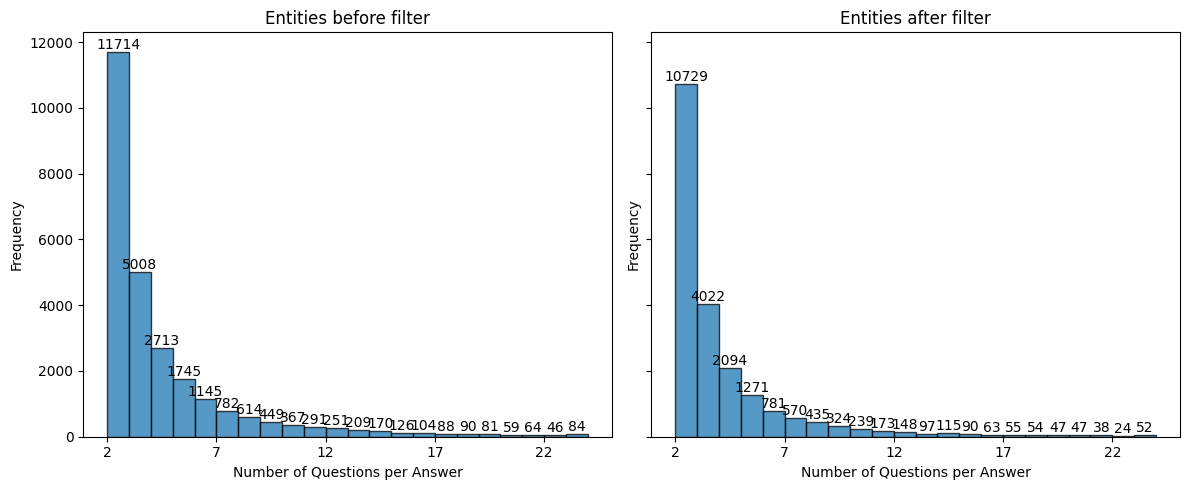

21820 out of 26766 remain after filtering (82%).


In [36]:
plot_answer_distributions({'Entities before filter': ent_clusters, 'Entities after filter': filtered_ent_clusters})
remain_clusters = {}
for answer, questions in filtered_ent_clusters.items():
    if len(questions) >= 2:
        remain_clusters[answer] = questions
print(f'{len(remain_clusters)} out of {len(ent_clusters)} remain after filtering ({round(100 * len(remain_clusters) / len(ent_clusters))}%).')

In [40]:
# Save in folder:
output_path = f"{REPO_PATH}\data_files\\filtered_cluster_ents.json"
with open(output_path, "w", encoding="utf-8") as out_file:
    json.dump(filtered_ent_clusters, out_file)

In [41]:
# Load from folder:
filtered_ent_clusters = load_json(f"{REPO_PATH}\data_files\\filtered_cluster_ents.json")

## 3.2 - Cluster and filter numerical questions:

**Structure numericals:**
1. '-' before the number.
2. hundred, thousand, million, billion ...
3. one, two, three, four ... (up to twelve)
4. spans (regex?)

In [32]:
import re

NUMBERS = {
    'one': 1, 'two': 2, 'three': 3, 'four': 4, 'five': 5,
    'six': 6, 'seven': 7, 'eight': 8, 'nine': 9, 'ten': 10,
    'eleven': 11, 'twelve': 12, 'thirteen': 13, 'fourteen': 14,
    'fifteen': 15, 'sixteen': 16, 'seventeen': 17, 'eighteen': 18,
    'nineteen': 19, 'twenty': 20, 'thirty': 30, 'forty': 40,
    'fifty': 50, 'sixty': 60, 'seventy': 70, 'eighty': 80,
    'ninety': 90, 'one hundred': 100
}
QUANTITIES = {'hundred': 100, 'thousand': 1_000, 'million': 1_000_000, 'billion': 1_000_000_000}
FRACTIONS = {'half': 0.5, 'quarter': 0.25, 'third': 1/3}

def extract_number(answer: str):
    """
    Extract numerical values from a string, handling words, ranges, and quantities.

    Args:
        answer (str): The input string containing numbers.

    Returns:
        int | float | str: Extracted number as int if possible, else float, or original string if no numbers exist.
    """
    # Remove commas inside numbers (e.g., "121,364" → "121364")
    answer = re.sub(r'(\d),(\d)', r'\1\2', answer)

    # Remove special characters but keep decimal points inside numbers
    answer = re.sub(r"[^\w\s.]|(?<=\d)\.(?=\D)|(?<=\D)\.(?=\d)", "", answer)

    # Handle ranges like "10-30" → take the midpoint
    range_match = re.search(r'(-?\d+\.?\d*)\s*-\s*(-?\d+\.?\d*)', answer)
    if range_match:
        num1, num2 = map(float, range_match.groups())
        midpoint = (num1 + num2) / 2
        return int(midpoint) if midpoint.is_integer() else midpoint

    # Replace number words with digits
    words = answer.lower().split()
    total = 0
    current_num = 0
    has_num = False

    for word in words:
        if word.replace('.', '', 1).isdigit():  # Check if it's a valid number (including floats)
            current_num = float(word)  # Update current number
            has_num = True
        elif word in NUMBERS:
            if current_num == 0:
                current_num = NUMBERS[word]  # Convert number words
            else:
                current_num += NUMBERS[word]
            has_num = True
        elif word in QUANTITIES:
            if not has_num:
                current_num = 1  # If "million" appears alone, assume "1 million"
            current_num *= QUANTITIES[word]  # Multiply the previous number by the quantity
            total += current_num
            current_num = 0  # Reset after applying multiplier
            has_num = True
        elif word in FRACTIONS:
            fraction_value = FRACTIONS[word]
            if has_num:
                current_num += fraction_value
            else:
                current_num = fraction_value
            has_num = True
        else:
            continue

    total += current_num  # Add any remaining value

    if total > 0:
        try:
            if total.is_integer():
                return int(total)
        except:
            return total

    # Extract numeric values including decimals
    num_match = re.findall(r'[-]?\d+\.?\d*', answer)
    if num_match:
        num = float(num_match[0])
        return int(num) if num.is_integer() else num

    return answer  # If no numeric content is found, return original string

In [20]:
print(extract_number('7 million'))
print(extract_number('121,364 square miles'))
print(extract_number('1.5 million'))
print(extract_number('$5 million'))
print(extract_number('0.03 mph'))
print(extract_number('£22,590,829'))

7000000
121364
1500000
5000000
0.03
22590829


In [22]:
import numpy as np
print(np.mean([isinstance(extract_number(sample['Answer']), int) or isinstance(extract_number(sample['Answer']), float) for sample in num_data]))
print(np.mean([isinstance(extract_number(sample['Answer']), float) for sample in num_data]))
print(np.mean([isinstance(extract_number(sample['Answer']), int) for sample in num_data]))

0.9798545047565753
0.059932848349188585
0.9199216564073867


In [33]:
print(extract_number("Twenty one feet"))
print(extract_number("Forty two"))

21
42


In [34]:
num_unstructured = 0
unstructured_ans = []
for sample in num_data:
    if not isinstance(extract_number(sample['Answer']), int) and not isinstance(extract_number(sample['Answer']), float):
        # print(extract_number(sample['Answer']))
        num_unstructured += 1
        unstructured_ans.append(sample['Answer'])
    else:
        print(f"{sample['Answer']} --> {extract_number(sample['Answer'])}")
# print(num_unstructured)
# print(len(set(unstructured_ans)))
# unstructured_ans

121,364 square miles --> 121364
53,187 --> 53187
6 --> 6
7 million --> 7000000
Mercury-Atlas 6 --> 6
60 feet --> 60
$85,000 --> 85000
$85,000 --> 85000
10 --> 10
Three --> 3
Five --> 5
1.5 million --> 1500000
11 --> 11
2,343 --> 2343
Twenty one feet --> 21
24 --> 24
58 --> 58
82 --> 82
76 --> 76
68 --> 68
22,300 --> 22300
81,823 --> 81823
69 --> 69
7,417 square miles --> 7417
82,751 square miles --> 82751
82,751 square miles --> 82751
145,556 square miles --> 145556
145,556 square miles --> 145556
32 --> 32
80 --> 80
38 --> 38
Three --> 3
$5 million --> 5000000
82,168 --> 82168
104 --> 104
44,820 square miles --> 44820
Eight --> 8
Nine --> 9
72 --> 72
100 --> 100
13 --> 13
2032 --> 2032
Nine --> 9
39 --> 39
47,687 square miles --> 47687
77 --> 77
92 --> 92
Two --> 2
27 --> 27
40,000 --> 40000
1,068 --> 1068
Eight --> 8
Nine --> 9
105 --> 105
58,900 square miles --> 58900
80 --> 80
114,000 square miles --> 114000
14 --> 14
122 --> 122
569 --> 569
Eight --> 8
42 --> 42
Four --> 4
Two -->

Clustering Entity Questions: 100%|██████████████████████████████████████████| 17870/17870 [00:00<00:00, 1559133.24it/s]


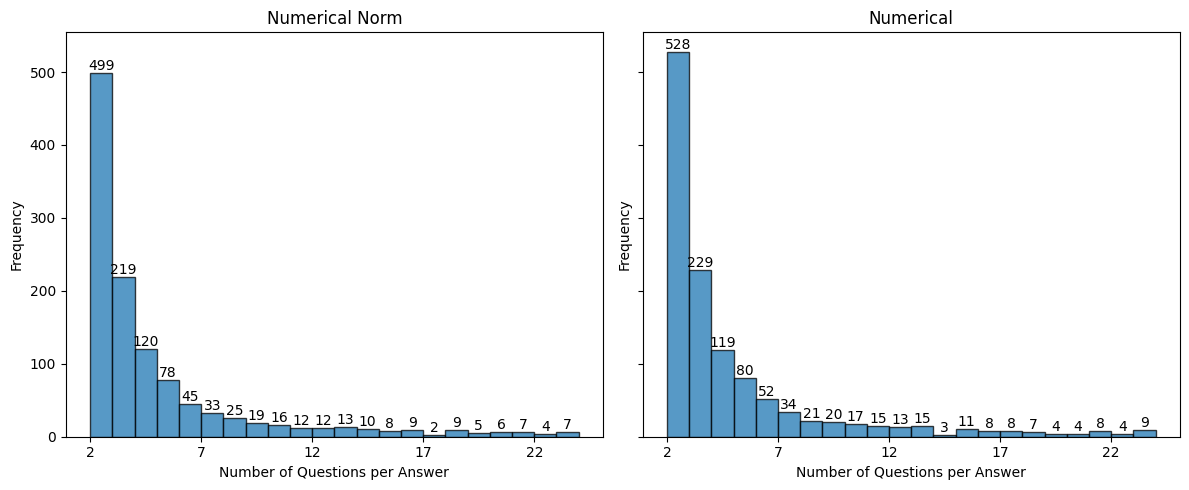

In [33]:
normalized_numericals = [extract_number(sample['Answer']) for sample in num_data]
clustered_normalized_numericals = cluster_wiki_entities([{'Question': sample['Question'], 'Normalized answer': answer} for sample, answer in zip(num_data, normalized_numericals)])

plot_answer_distributions({'Numerical Norm': clustered_normalized_numericals, 'Numerical': num_clusters})

In [60]:
BINS = [
    (0, 10), (11, 50), (51, 100), (101, 500), (501, 1000),  
    (1001, 5000), (5001, 10_000), (10_001, 50_000), (50_001, 100_000),
    (100_001, 500_000), (500_001, 1_000_000),  
    (1_000_001, 10_000_000), (10_000_001, 100_000_000), (100_000_001, 1_000_000_000), (1_000_000_001, float("inf"))
]

def assign_to_bin(number, bins):
    """Assign a number to a predefined bin."""
    for lower, upper in bins:
        if lower <= number <= upper:
            return (lower, upper)  # Return the bin range
    return None  # Should never happen if bins are well-defined

# Example usage:
cands = list(clustered_normalized_numericals)
numbers = []
for cand in cands:
    if isinstance(cand, int):
        numbers.append(cand)
binned_numbers = {num: assign_to_bin(num, BINS) for num in numbers}

for num, bin_range in binned_numbers.items():
    print(f"{num} → Bin: {bin_range}")

1 → Bin: (0, 10)
2 → Bin: (0, 10)
3 → Bin: (0, 10)
4 → Bin: (0, 10)
5 → Bin: (0, 10)
6 → Bin: (0, 10)
7 → Bin: (0, 10)
8 → Bin: (0, 10)
9 → Bin: (0, 10)
10 → Bin: (0, 10)
11 → Bin: (11, 50)
12 → Bin: (11, 50)
13 → Bin: (11, 50)
14 → Bin: (11, 50)
15 → Bin: (11, 50)
16 → Bin: (11, 50)
17 → Bin: (11, 50)
18 → Bin: (11, 50)
19 → Bin: (11, 50)
20 → Bin: (11, 50)
22 → Bin: (11, 50)
23 → Bin: (11, 50)
24 → Bin: (11, 50)
25 → Bin: (11, 50)
26 → Bin: (11, 50)
27 → Bin: (11, 50)
28 → Bin: (11, 50)
21 → Bin: (11, 50)
30 → Bin: (11, 50)
29 → Bin: (11, 50)
32 → Bin: (11, 50)
33 → Bin: (11, 50)
35 → Bin: (11, 50)
36 → Bin: (11, 50)
37 → Bin: (11, 50)
38 → Bin: (11, 50)
39 → Bin: (11, 50)
40 → Bin: (11, 50)
41 → Bin: (11, 50)
42 → Bin: (11, 50)
43 → Bin: (11, 50)
44 → Bin: (11, 50)
45 → Bin: (11, 50)
46 → Bin: (11, 50)
48 → Bin: (11, 50)
49 → Bin: (11, 50)
50 → Bin: (11, 50)
51 → Bin: (51, 100)
52 → Bin: (51, 100)
53 → Bin: (51, 100)
54 → Bin: (51, 100)
55 → Bin: (51, 100)
56 → Bin: (51, 100)
57 → B

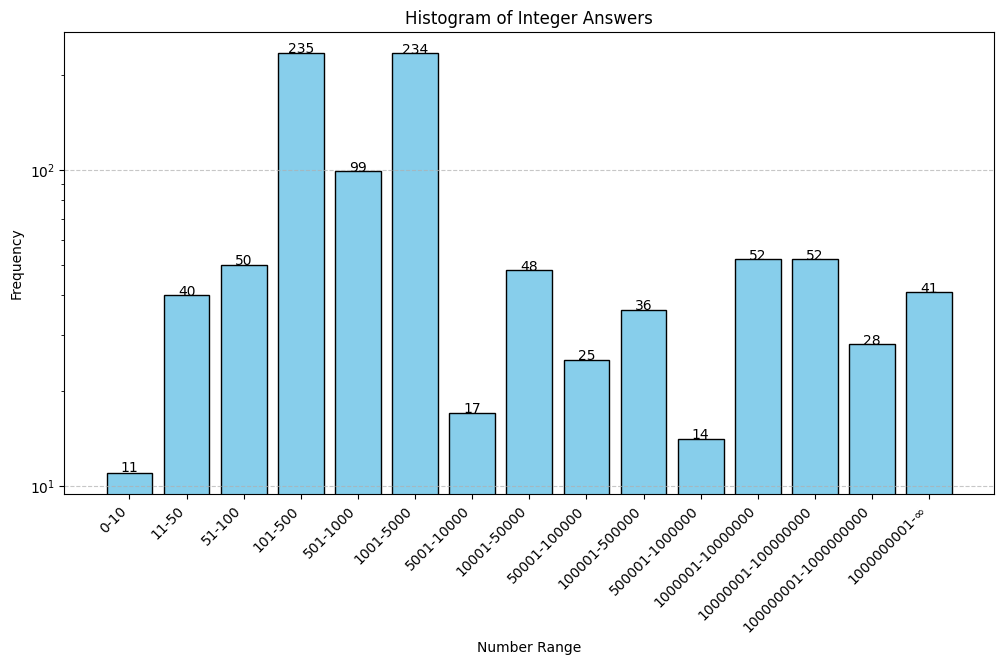

In [61]:
# Assign numbers to bins
bin_counts = {bin_range: 0 for bin_range in BINS}
for num in numbers:
    for bin_range in BINS:
        if bin_range[0] <= num <= bin_range[1]:
            bin_counts[bin_range] += 1
            break

# Prepare x-axis labels & y-values
bin_labels = [f"{low}-{high if high != float('inf') else '∞'}" for low, high in BINS]
counts = list(bin_counts.values())

# Plot histogram
plt.figure(figsize=(12, 6))
plt.bar(bin_labels, counts, color="skyblue", edgecolor="black")
plt.xticks(rotation=45, ha="right")
plt.ylabel("Frequency")
plt.xlabel("Number Range")
plt.title("Histogram of Integer Answers")
plt.yscale("log")  # Log scale to handle large variations
plt.grid(axis="y", linestyle="--", alpha=0.7)

# Display values on top of bars
for i, count in enumerate(counts):
    plt.text(i, count + 0.1, str(count), ha="center", fontsize=10)

plt.show()

## 3.3 - Cluster and filter date & time questions:

In [114]:
import re

MONTHS = ['January', 'February', 'March', 'April', 'May', 'June', 
          'July', 'August', 'September', 'October', 'November', 'December']
DAYS = ['Sunday', 'Monday', 'Tuesday', 'Wednesday', 'Thursday', 'Friday', 'Saturday']

# Categorized lists
day_answers = []
month_answers = []
year_answers = []
decade_answers = []
centuries_answers = []
generic_month_answers = []
generic_days_answers = []
full_date_answers = []
year_span_answers = []
rest_data = []

# Regex pattern for different year span formats, including shorthand years (e.g., "1933 -- 35")
YEAR_SPAN_PATTERN = re.compile(r'(\d{4})\s*[-–—]{1,2}\s*(\d{2,4})|(\d{4})\s+to\s+(\d{2,4})', re.IGNORECASE)

for sample in date_data:
    answer = sample['Answer']
    words = answer.split()

    # Case: Full date (day, month, year in any order)
    if any(month in words for month in MONTHS) and any(word.isdigit() and len(word) == 4 for word in words) and any(word.isdigit() and len(word) <= 2 for word in words):
        full_date_answers.append(answer)

    # Case: Year span (handles "YYYY - YYYY", "YYYY -- YYYY", "YYYY — YYYY", "YYYY to YYYY", AND "YYYY -- YY")
    elif YEAR_SPAN_PATTERN.search(answer):
        match = YEAR_SPAN_PATTERN.search(answer)
        year1 = int(match.group(1) or match.group(3))  # First year
        year2 = match.group(2) or match.group(4)  # Second year (could be short form)

        # If year2 is a two-digit year, expand it correctly
        if year2 and len(year2) == 2:
            base_year = year1 // 100 * 100  # Get the century part (e.g., 1900 for 1933)
            year2 = base_year + int(year2)  # Convert "35" → "1935"

        year_span_answers.append(f"{year1} - {year2}")

    # Case: Month + Year in any order (e.g., "March 2020" or "2020 March")
    elif len(words) == 2 and any(word in MONTHS for word in words) and any(word.isdigit() and len(word) == 4 for word in words):
        month_answers.append(answer)

    # Case: Day + Month in any order (e.g., "March 15" or "15 March")
    elif len(words) == 2 and any(word in MONTHS for word in words) and any(word.isdigit() and len(word) <= 2 for word in words):
        day_answers.append(answer)

    # Case: Single year (e.g., "1999")
    elif len(words) == 1 and words[0].isdigit() and int(words[0]) > 1000:
        year_answers.append(answer)

    # Case: Decades (e.g., "1920s")
    elif len(words) == 1 and words[0][-1] == 's' and words[0][:-1].isdigit():
        decade_answers.append(answer)

    # Case: Centuries (e.g., "18th century", "20th century")
    elif 'century' in answer:
        centuries_answers.append(answer)

    # Case: Generic Month (e.g., "July")
    elif len(words) == 1 and words[0] in MONTHS:
        generic_month_answers.append(answer)

    # Case: Generic Day (e.g., "Monday")
    elif len(words) == 1 and words[0] in DAYS:
        generic_days_answers.append(answer)

    else:
        rest_data.append(answer)

# Print results
print('days: ', len(day_answers))
print('generic days: ', len(generic_days_answers))
print('months: ', len(month_answers))
print('generic months: ', len(generic_month_answers))
print('years: ', len(year_answers))
print('decades: ', len(decade_answers))
print('centuries: ', len(centuries_answers))
print('full dates: ', len(full_date_answers))
print('year spans: ', len(year_span_answers))
print('rest: ', len(rest_data))

days:  546
generic days:  97
months:  1455
generic months:  353
years:  12169
decades:  423
centuries:  526
full dates:  1932
year spans:  506
rest:  3452


In [115]:
sorted(rest_data)

['"Class of \'67"',
 '"Fourth of June"',
 '"Late Qing Reform"',
 '"Ten-Year Housing Plan"',
 "'07",
 '( 1987 )',
 '(1992)',
 '(2000',
 '(2006)',
 '(24 June)',
 '(309239) 2007 RW10',
 '1 day',
 '1,400 years',
 '1,500 BCE',
 '1,800 years ago',
 '1.2 years',
 '1.2 years longer',
 '10 Days',
 '10 YEARS',
 '10 days',
 '10 days',
 '10 days',
 '10 days',
 '10 days',
 '10 months',
 '10 months',
 '10 months',
 '10 months',
 '10 weeks',
 '10 years',
 '10 years',
 '10 years',
 '10 years',
 '10 years',
 '10 years',
 '10 years',
 '10 years old',
 '10,000 years ago',
 '10,000 years ago',
 '10,000 years ago',
 '10,000 years ago',
 '10-year',
 '10-year',
 '10.12. 6',
 '10.13. 6',
 '10.13. 6',
 '10/11 May 1941',
 '10/13 Communications',
 '100 Years',
 '100 years',
 '100 years',
 '100 years',
 '1000 CE',
 '1046 BC',
 '105 AD',
 '1066 AD',
 '108 - year',
 '10th millennium BC',
 '10th millennium BC',
 '11 May 330',
 '11 years',
 '11,000 years ago',
 '11.5 months',
 '110 million years',
 '1100 BC',
 '114 B

In [122]:
for sample in date_data:
    if sample['Answer'] == '20 years':
        print(sample['Question'])

What is the minimum alcohol drinking age in bars in Iceland?
How long is a US patent good for (as of June 9, 1995)?
how long did it take to build great pyramid of giza
Approximately how long did it take to build New Delhi?
How long does it take for patents to expire after being filed?
How long do drug exclusivity rights usually last?
How long had Richard Gephart served in house prior to being elected to minority leader?


In [102]:
import re

MONTHS = ['January', 'February', 'March', 'April', 'May', 'June', 
          'July', 'August', 'September', 'October', 'November', 'December']
DAYS = ['Sunday', 'Monday', 'Tuesday', 'Wednesday', 'Thursday', 'Friday', 'Saturday']

# Regex pattern for different year span formats, including shorthand years (e.g., "1933 -- 35")
YEAR_SPAN_PATTERN = re.compile(r'(\d{4})\s*[-–—]{1,2}\s*(\d{2,4})|(\d{4})\s+to\s+(\d{2,4})', re.IGNORECASE)

def parse_date_samples(date_data):
    structured_data = []
    
    for sample in date_data:
        answer = sample['Answer']
        
        # Strip unnecessary punctuation and whitespace
        answer = re.sub(r'[.,]', '', answer).strip()
        words = answer.split()
        
        # Remove unnecessary words
        words = [word for word in words if word.lower() not in ('in', 'early', 'mid', 'late')]
        answer_cleaned = ' '.join(words)  # Reconstruct string after filtering
        category = 'unknown'

        # Case: Full date (day, month, year in any order)
        if any(month in words for month in MONTHS) and any(word.isdigit() and len(word) == 4 for word in words) and any(word.isdigit() and len(word) <= 2 for word in words):
            category = 'full_date'
            day = next((word for word in words if word.isdigit() and len(word) <= 2), '')
            month = next((word for word in words if word in MONTHS), '')
            year = next((word for word in words if word.isdigit() and len(word) == 4), '')
            answer_cleaned = f"{day} {month} {year}".strip()
        
        # Case: Year span (handles "YYYY - YYYY", "YYYY -- YYYY", "YYYY — YYYY", "YYYY to YYYY", AND "YYYY -- YY")
        elif YEAR_SPAN_PATTERN.search(answer_cleaned):
            match = YEAR_SPAN_PATTERN.search(answer_cleaned)
            year1 = int(match.group(1) or match.group(3))  # First year
            year2 = match.group(2) or match.group(4)  # Second year (could be short form)
            
            # If year2 is a two-digit year, expand it correctly
            if year2 and len(year2) == 2:
                base_year = year1 // 100 * 100  # Get the century part (e.g., 1900 for 1933)
                year2 = base_year + int(year2)  # Convert "35" → "1935"
            
            answer_cleaned = f"{year1} - {year2}"
            category = 'year_span'
        
        # Case: Month + Year in any order (e.g., "March 2020" or "2020 March")
        elif len(words) == 2 and any(word in MONTHS for word in words) and any(word.isdigit() and len(word) == 4 for word in words):
            category = 'month_year'
            month = next((word for word in words if word in MONTHS), '')
            year = next((word for word in words if word.isdigit() and len(word) == 4), '')
            answer_cleaned = f"{month} {year}".strip()
        
        # Case: Day + Month in any order (e.g., "March 15" or "15 March")
        elif len(words) == 2 and any(word in MONTHS for word in words) and any(word.isdigit() and len(word) <= 2 for word in words):
            category = 'day_month'
            day = next((word for word in words if word.isdigit() and len(word) <= 2), '')
            month = next((word for word in words if word in MONTHS), '')
            answer_cleaned = f"{day} {month}".strip()
        
        # Case: Single year (e.g., "1999")
        elif len(words) == 1 and words[0].isdigit() and int(words[0]) > 1000:
            category = 'year'
        
        # Case: Decades (e.g., "1920s")
        elif len(words) == 1 and words[0][-1] == 's' and words[0][:-1].isdigit():
            category = 'decade'
            answer_cleaned = words[0][:-1]  # Remove 's' to keep only the number
            if len(answer_cleaned) < 4:
                answer_cleaned = '19' + answer_cleaned
        
        # Case: Centuries (e.g., "18th century", "20th century")
        elif 'century' in answer_cleaned:
            category = 'century'
            if re.search(r'\d+', answer_cleaned):
                answer_cleaned = re.search(r'\d+', answer_cleaned).group()
            else:
                category = 'unknown'
        
        # Case: Generic Month (e.g., "July")
        elif len(words) == 1 and words[0] in MONTHS:
            category = 'generic_month'
        
        # Case: Generic Day (e.g., "Monday")
        elif len(words) == 1 and words[0] in DAYS:
            category = 'generic_day'
        
        structured_data.append({'category': category, 'parsed_value': answer_cleaned})
    
    return structured_data

In [104]:
problems = []
for dddd, sample in zip(date_data, parse_date_samples(date_data)):
    if sample['category'] == 'century':
        problems.append(sample)

sorted(set([problem['parsed_value'] for problem in problems]))

['1',
 '10',
 '11',
 '12',
 '13',
 '14',
 '15',
 '16',
 '17',
 '18',
 '19',
 '2',
 '20',
 '21',
 '26',
 '29',
 '3',
 '30',
 '31',
 '4',
 '5',
 '6',
 '7',
 '8',
 '9']

In [105]:
MONTHS = ['January', 'February', 'March', 'April', 'May', 'June', 
          'July', 'August', 'September', 'October', 'November', 'December']
DAYS = ['Sunday', 'Monday', 'Tuesday', 'Wednesday', 'Thursday', 'Friday', 'Saturday']

# Regex pattern for different year span formats, including shorthand years (e.g., "1933 -- 35")
YEAR_SPAN_PATTERN = re.compile(r'(\d{4})\s*[-–—]{1,2}\s*(\d{2,4})|(\d{4})\s+to\s+(\d{2,4})', re.IGNORECASE)

def extract_date(answer: str) -> dict:
        
    # Strip unnecessary punctuation and whitespace
    answer = re.sub(r'[.,]', '', answer).strip()
    words = answer.split()
    
    # Remove unnecessary words
    words = [word for word in words if word.lower() not in ('in', 'early', 'mid', 'late')]
    answer_cleaned = ' '.join(words)  # Reconstruct string after filtering
    category = 'unknown'

    # Case: Full date (day, month, year in any order)
    if any(month in words for month in MONTHS) and any(word.isdigit() and len(word) == 4 for word in words) and any(word.isdigit() and len(word) <= 2 for word in words):
        category = 'full_date'
        day = next((word for word in words if word.isdigit() and len(word) <= 2), '')
        month = next((word for word in words if word in MONTHS), '')
        year = next((word for word in words if word.isdigit() and len(word) == 4), '')
        answer_cleaned = f"{day} {month} {year}".strip()
    
    # Case: Year span (handles "YYYY - YYYY", "YYYY -- YYYY", "YYYY — YYYY", "YYYY to YYYY", AND "YYYY -- YY")
    elif YEAR_SPAN_PATTERN.search(answer_cleaned):
        match = YEAR_SPAN_PATTERN.search(answer_cleaned)
        year1 = int(match.group(1) or match.group(3))  # First year
        year2 = match.group(2) or match.group(4)  # Second year (could be short form)
        
        # If year2 is a two-digit year, expand it correctly
        if year2 and len(year2) == 2:
            base_year = year1 // 100 * 100  # Get the century part (e.g., 1900 for 1933)
            year2 = base_year + int(year2)  # Convert "35" → "1935"
        
        answer_cleaned = f"{year1} - {year2}"
        category = 'year_span'
    
    # Case: Month + Year in any order (e.g., "March 2020" or "2020 March")
    elif len(words) == 2 and any(word in MONTHS for word in words) and any(word.isdigit() and len(word) == 4 for word in words):
        category = 'month_year'
        month = next((word for word in words if word in MONTHS), '')
        year = next((word for word in words if word.isdigit() and len(word) == 4), '')
        answer_cleaned = f"{month} {year}".strip()
    
    # Case: Day + Month in any order (e.g., "March 15" or "15 March")
    elif len(words) == 2 and any(word in MONTHS for word in words) and any(word.isdigit() and len(word) <= 2 for word in words):
        category = 'day_month'
        day = next((word for word in words if word.isdigit() and len(word) <= 2), '')
        month = next((word for word in words if word in MONTHS), '')
        answer_cleaned = f"{day} {month}".strip()
    
    # Case: Single year (e.g., "1999")
    elif len(words) == 1 and words[0].isdigit() and int(words[0]) > 1000:
        category = 'year'
    
    # Case: Decades (e.g., "1920s")
    elif len(words) == 1 and words[0][-1] == 's' and words[0][:-1].isdigit():
        category = 'decade'
        answer_cleaned = words[0][:-1]  # Remove 's' to keep only the number
        if len(answer_cleaned) < 4:
            answer_cleaned = '19' + answer_cleaned
    
    # Case: Centuries (e.g., "18th century", "20th century")
    elif 'century' in answer_cleaned:
        category = 'century'
        if re.search(r'\d+', answer_cleaned):
            answer_cleaned = re.search(r'\d+', answer_cleaned).group()
        else:
            category = 'unknown'
    
    # Case: Generic Month (e.g., "July")
    elif len(words) == 1 and words[0] in MONTHS:
        category = 'generic_month'
    
    # Case: Generic Day (e.g., "Monday")
    elif len(words) == 1 and words[0] in DAYS:
        category = 'generic_day'
        
    return {'category': category, 'parsed_value': answer_cleaned}

In [131]:
from random import choice

extract_date(choice(date_data)['Answer'])

{'category': 'full_date', 'parsed_value': '26 January 1950'}

# 4. Create paragraphs: